In [18]:
from pyspark.sql import SparkSession
import re
from wordcloud import WordCloud
from matplotlib import pyplot as plt

spark = SparkSession.builder.getOrCreate()

In [ ]:
text_rdd = spark.sparkContext.textFile("books/RomeoJuliet.txt")

In [20]:
def clean_and_tokenize(line):
    line = line.lower()
    line = re.sub(r'[^a-z\s]', ' ', line)
    words = line.split()
    return words

In [ ]:
words_rdd = text_rdd.flatMap(clean_and_tokenize)

with open('stop_words_english.txt', 'r') as f:
    STOP_WORDS_EN = set(f.read().splitlines())

filtered_words_rdd = words_rdd.filter(lambda word: word not in STOP_WORDS_EN and len(word) > 2)

In [ ]:
word_counts_rdd = filtered_words_rdd.map(lambda word: (word, 1)) \
    .reduceByKey(lambda a, b: a + b)

final_word_counts = word_counts_rdd.collectAsMap()

In [ ]:
spark.stop()

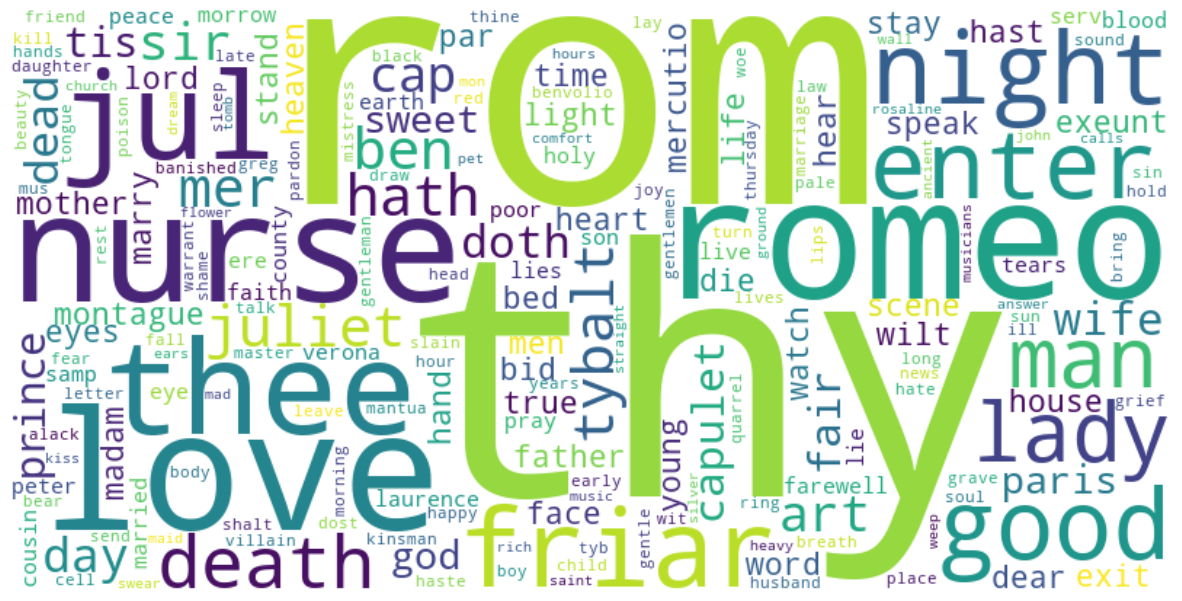

In [23]:
wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color='white', 
    max_words=200, 
    min_font_size=4, 
    collocations=False
)

wordcloud.generate_from_frequencies(final_word_counts)

plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()